# QBISAC allocation and local ranging

## Study inputs

The main example uses five frequency offsets and three signal brightnesses. Each energy cap is expressed in units of one photon at the carrier frequency. In the memory study the 3.98 µs lifetime is experimentally informed and the longer lifetimes are assumed.

The allocation bound is calculated below. Figures 5.3, 5.4 and 5.6 use saved optimisation runs.

In [1]:
import json
from fractions import Fraction
from pathlib import Path

from IPython.display import Markdown, display

# Read the archived data from this notebook. Batch runs use the repository filename.
notebook_path = Path(globals().get("__vsc_ipynb_file__") or globals().get("__session__")
                     or "QBISAC_allocation.ipynb")
if not notebook_path.is_file():
    notebook_path = Path(notebook_path.name)
with notebook_path.open(encoding="utf-8") as file:
    study_inputs = json.load(file)["metadata"]["qbisac"]["study_inputs"]

main_case = study_inputs["central"]
memory = study_inputs["memory_lifetimes"]
M = main_case["M"]
E = Fraction(main_case["E"])
C = Fraction(main_case["C"])
lifetimes_us = ", ".join(f'{row["lifetime_us"]:.2f}'.rstrip("0").rstrip(".")
                         for row in memory["studies"])

display(Markdown(f'''| Setting | Main example | Memory study |
|:---|---:|---:|
| Preparations, M | {M:,} | {memory["preparation_cap"]:,} |
| Signal-energy cap, E | {float(E):g} | {float(Fraction(memory["energy_cap"])):,g} |
| Target exponent, C | ≈{float(C):.4f} | ≈{float(Fraction(memory["communication_target"])):.4f} |
| Idler | Ideal | {lifetimes_us} µs |'''))

| Setting | Main example | Memory study |
|:---|---:|---:|
| Preparations, M | 240 | 100,000 |
| Signal-energy cap, E | 9.6 | 4,000 |
| Target exponent, C | ≈2.7404 | ≈2.7404 |
| Idler | Ideal | 3.98, 8, 14, 20 µs |

## Physical model and coefficient check

In [2]:
%matplotlib inline
from dataclasses import dataclass
from decimal import Decimal, localcontext
from hashlib import sha256
from itertools import product
from math import ceil, floor, lcm, sqrt

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False})


@dataclass(frozen=True)
class Option:
    frequency: int
    brightness: Fraction
    energy: Fraction
    exponent: Fraction
    weight: Fraction


def outward_percent(value, *, upper=False):
    """Round an exact percentage outwards to four decimal places, without a float."""
    units = (ceil if upper else floor)(value * 10_000)
    whole, decimals = divmod(abs(units), 10_000)
    return f"{'-' if units < 0 else ''}{whole}.{decimals:04d}%"

In [3]:
# Selected-mode parameters in Thesis Table 3.2, original profile and ideal idler.
indices = (-2, -1, 0, 1, 2)
path_transmission = tuple(map(Fraction, ("0.175", "0.28", "0.35", "0.28", "0.175")))
brightness = tuple(map(Fraction, ("0.02", "0.04", "0.08")))
collection, bath, carrier_times_T = Fraction("0.5"), Fraction("0.15"), 1000


def paired_exponent(n_return, n_idler, corr_squared):
    # Known-phase BPSK, opposite pair correlations. Vacuum covariance is I.
    with localcontext() as ctx:
        ctx.prec = 50
        nr, ni, m2 = [Decimal(x.numerator) / Decimal(x.denominator)
                      for x in (n_return, n_idler, corr_squared)]
        a, b, c_squared = 2 * ni + 1, 2 * nr + 1, 4 * m2
        d_squared = (a + b)**2 - 4 * c_squared
        d, gap = d_squared.sqrt(), abs(a - b)
        nu_high, nu_low = (d + gap) / 2, (d - gap) / 2
        mu_high, mu_low = [v + (v**2 - 1).sqrt() for v in (nu_high, nu_low)]
        argument = c_squared * (mu_high + mu_low)**2 / (d_squared * mu_high * mu_low)
        return float((1 + argument).ln())


def regenerate_options():
    options = []
    for index, eta in zip(indices, path_transmission, strict=True):
        t, background = collection * eta, (1 - eta) * bath
        for photons in brightness:
            nr, ni = t * photons + background, photons
            m2 = t * photons * (photons + 1)
            weight = 4 * m2 / (2 * nr * ni + nr + ni + 1 - 2 * m2)
            energy = photons * (1 + Fraction(index, carrier_times_T))
            xi = Fraction.from_float(paired_exponent(nr, ni, m2))
            options.append(Option(index, photons, energy, xi, weight))
    return options


archived_options = [
    Option(row["n"], Fraction(row["N"]), Fraction(row["e"]), Fraction(row["xi"]), Fraction(row["w"]))
    for row in main_case["options"]
]
options = regenerate_options()
# The archived exponents are exact fractions of the floats returned by the physical model.
assert options == archived_options
central = next(o for o in options if o.frequency == 0 and o.brightness == Fraction("0.04"))
print(f"Regenerated {len(options)} catalogue options. Central N = 0.04: "
      f"xi = {float(central.exponent):.10f}, w = {float(central.weight):.10f}")

Regenerated 15 catalogue options. Central N = 0.04: xi = 0.0228366579, w = 0.0255820083


## Minimum communication count and feasible allocation

In [4]:
max_exponent = max(o.exponent for o in options)
minimum = ceil(C / max_exponent)
index = {(o.frequency, o.brightness): j for j, o in enumerate(options)}
dim, mid = (index[0, p] for p in brightness[:2])
left, right = index[-2, brightness[-1]], index[2, brightness[-1]]


def ranging_score(frequencies, phase_weights):
    """Local delay score with one unknown common phase. Each weight includes its copy count."""
    A0 = sum(phase_weights)
    if A0 == 0:
        return Fraction(0)
    terms = list(zip(frequencies, phase_weights, strict=True))
    A1 = sum(weight * n for n, weight in terms)
    A2 = sum(weight * n**2 for n, weight in terms)
    return A2 - A1**2 / A0


def score_design(c, s):
    assert all(type(n) is int and n >= 0 for n in c + s)
    comm_energy = sum(n * o.energy for n, o in zip(c, options, strict=True))
    ranging_energy = sum(n * o.energy for n, o in zip(s, options, strict=True))
    exponent = sum(n * o.exponent for n, o in zip(c, options, strict=True))
    phase_weights = [n * o.weight for n, o in zip(s, options, strict=True)]
    score = ranging_score([o.frequency for o in options], phase_weights)
    return comm_energy, ranging_energy, exponent, score


# Communication uses the centre frequency. Split bright ranging shots between the two outer modes.
# For each count m, use the fewest intermediate-brightness shots needed to reach C.
feasible = []
for m in range(M + 1):
    n_mid = max(0, ceil((C - m * options[dim].exponent)
                        / (options[mid].exponent - options[dim].exponent)))
    if n_mid > m:
        continue
    c, s = [0] * len(options), [0] * len(options)
    c[dim], c[mid] = m - n_mid, n_mid
    s[left], s[right] = (M - m + 1) // 2, (M - m) // 2
    ec, es, exponent, score = score_design(c, s)
    if ec + es <= E and exponent >= C:
        feasible.append((score, c, s))

F_full, c_full, s_full = max(feasible, key=lambda row: row[0])
saved_allocations = main_case["original"]
assert (c_full, s_full) == (saved_allocations["full"]["c"], saved_allocations["full"]["s"])
c_min, s_min = saved_allocations["restricted"]["c"], saved_allocations["restricted"]["s"]
ec_min, es_min, xi_min, F_min = score_design(c_min, s_min)
ec_full, es_full, xi_full, _ = score_design(c_full, s_full)
assert sum(c_min) == minimum and sum(c_min + s_min) <= M and ec_min + es_min <= E and xi_min >= C
for score, key in [(F_full, "full"), (F_min, "restricted")]:
    assert score == Fraction(saved_allocations[key]["ledger"]["F_unshared"])

print(f"M = {M}, E = {float(E):g}, C = {float(C):.9f}")
print(f"{minimum - 1} strongest shots give {float((minimum - 1) * max_exponent):.9f}; "
      f"the feasible {minimum}-shot candidate reaches {float(xi_min):.9f}.")
print(f"Best in the searched family: {sum(c_full)} communication ({c_full[dim]} dim, {c_full[mid]} intermediate), "
      f"{sum(s_full)} ranging ({s_full[left]} left, {s_full[right]} right).")

M = 240, E = 9.6, C = 2.740398951
62 strongest shots give 2.706571293; the feasible 63-shot candidate reaches 2.750225668.
Best in the searched family: 179 communication (122 dim, 57 intermediate), 61 ranging (31 left, 30 right).


## Count and energy comparison (Figure 5.1)

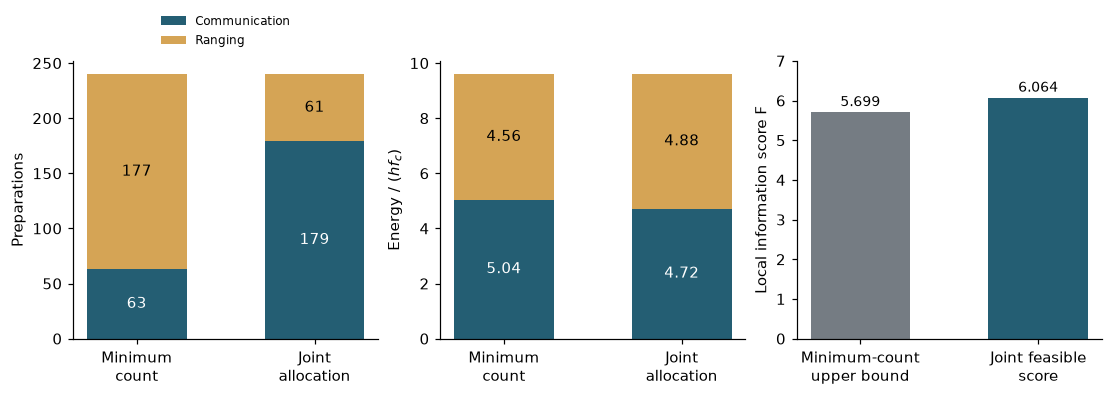

Communication saves 0.32 energy units; ranging uses 0.31984 more.
Conservative guarantee: at least 6.3899%.


In [5]:
figure_data = study_inputs["figures"]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
labels = ["Minimum\ncount", "Joint\nallocation"]
for ax, comm, sense, ylabel in [
    (axes[0], [sum(c_min), sum(c_full)], [sum(s_min), sum(s_full)], "Preparations"),
    (axes[1], [float(ec_min), float(ec_full)], [float(es_min), float(es_full)], "Energy / ($h f_c$)"),
]:
    ax.bar(labels, comm, color="#245e73", label="Communication", width=.56)
    ax.bar(labels, sense, bottom=comm, color="#d5a455", label="Ranging", width=.56)
    for i, (c_value, s_value) in enumerate(zip(comm, sense)):
        ax.text(i, c_value/2, f"{c_value:g}", ha="center", va="center", color="white")
        ax.text(i, c_value+s_value/2, f"{s_value:.3f}".rstrip("0").rstrip("."),
                ha="center", va="center")
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=8, loc="lower center", bbox_to_anchor=(.5, 1.01))

# Figure 5.1(c) uses the earlier whole-class upper bound, shown here for comparison.
old_min_upper = Fraction(saved_allocations["restricted"]["upper"])
scores = [float(old_min_upper), float(F_full)]
bars = axes[2].bar(["Minimum-count\nupper bound", "Joint feasible\nscore"], scores,
                   color=["#757c83", "#245e73"], width=.56)
axes[2].bar_label(bars, fmt="%.3f", fontsize=9, padding=2)
axes[2].set(ylabel="Local information score F", ylim=(0, 7))
plt.show()

assert np.allclose(scores, figure_data["allocation_comparison"]["scores"], rtol=1e-12, atol=0)
print(f"Communication saves {float(ec_min - ec_full):.2f} energy units; "
      f"ranging uses {float(es_full - es_min):.5f} more.")
print(f"Conservative guarantee: at least {outward_percent(100*(F_full/old_min_upper - 1))}.")

## Integer bound on the allocation gain (Table 5.4)

In [6]:
# At each brightness use the best exponent and best w*n². Dropping A₁²/A₀ bounds F from above.
levels = []
for photons in brightness:
    group = [o for o in options if o.brightness == photons]
    units = photons / brightness[0]
    assert units.denominator == 1
    levels.append((int(units), max(o.exponent for o in group),
                   max(o.weight * o.frequency**2 for o in group)))
cheapest_unit = min(o.energy / (o.brightness / brightness[0]) for o in options)
unit_cap = floor(E / cheapest_unit)
assert [p for p, _, _ in levels] == [1, 2, 4]


def integer_ceilings(limit, cap, target, fixed_count):
    exp_scale = lcm(target.denominator, *(x.denominator for _, x, _ in levels))
    reward_scale = lcm(*(r.denominator for _, _, r in levels))
    x1, x2, x4 = [int(x * exp_scale) for _, x, _ in levels]
    rewards = [(p, int(r * reward_scale)) for p, _, r in levels]
    threshold = int(target * exp_scale)

    # G[s][u] is the best ranging reward with at most s preparations and u brightness units.
    G = [[0] * (cap + 1) for _ in range(limit + 1)]
    for s in range(1, limit + 1):
        previous = G[s - 1]
        for u in range(cap + 1):
            best_reward = previous[u]  # Leave this preparation unused.
            for units, reward in rewards:
                if units <= u:
                    best_reward = max(best_reward, previous[u - units] + reward)
            G[s][u] = best_reward

    best_by_count = {}
    for m in range(limit + 1):
        for units in range(m, min(4 * m, cap) + 1):
            # m and units fix the dim and intermediate counts once the bright count is chosen.
            fewest_bright = max(0, (units - 2 * m + 1) // 2)
            most_bright = (units - m) // 3
            if fewest_bright > most_bright:
                continue
            # The exponent is linear in the bright count, so its maximum is at an endpoint.
            best_exponent = 0
            for bright in (fewest_bright, most_bright):
                dim = 2 * m - units + 2 * bright
                intermediate = units - m - 3 * bright
                best_exponent = max(best_exponent, dim * x1 + intermediate * x2 + bright * x4)
            if best_exponent >= threshold:
                remaining_reward = G[limit - m][cap - units]
                best_by_count[m] = max(best_by_count.get(m, 0), remaining_reward)

    full_ceiling = Fraction(max(best_by_count.values()), reward_scale)
    minimum_count_ceiling = Fraction(best_by_count[fixed_count], reward_scale)
    return full_ceiling, minimum_count_ceiling


U_full, U_min = integer_ceilings(M, unit_cap, C, minimum)
assert U_full == Fraction(main_case["exact_integer_certificates"]["joint"]["upper"])
assert U_min == Fraction(main_case["exact_integer_certificates"]["minimum_count"]["upper"])
gain_lo, gain_hi = 100*(F_full/U_min - 1), 100*(U_full/F_min - 1)
print(f"Cheapest energy per unit = {cheapest_unit}; energy cap permits {unit_cap} units.")
print(f"Joint feasible F = {float(F_full):.9f}; every minimum-count F ≤ {float(U_min):.9f}.")
print(f"Original unknown-phase gain: [{outward_percent(gain_lo)}, {outward_percent(gain_hi, upper=True)}].")
print(f"Corresponding reduction in the local SD bound: about {100*(1-1/sqrt(1+float(gain_lo)/100)):.2f}%.")

Cheapest energy per unit = 499/25000; energy cap permits 480 units.
Joint feasible F = 6.063521474; every minimum-count F ≤ 5.675845053.
Original unknown-phase gain: [6.8302%, 6.8591%].
Corresponding reduction in the local SD bound: about 3.25%.


## Check against a four-preparation search

In [7]:
# Small relaxed problem: enumerate idle, communication and ranging actions on four slots.
# This checks the integer optimisation separately from the physical coefficient calculation.
actions = [(0, 0, 0, 0)]  # communication count, units, exponent, ranging reward
for p, x, r in levels:
    actions.extend([(1, p, x, 0), (0, p, 0, r)])

small_designs = [tuple(sum(column) for column in zip(*design))
                 for design in product(actions, repeat=4)]
checked = 0
for cap in (8, 12, 16):
    for target in (levels[0][1], 2*levels[1][1], 2*levels[2][1], 3*levels[2][1], 4*levels[2][1]):
        allowed = [(count, reward) for count, units, exponent, reward in small_designs
                   if units <= cap and exponent >= target]
        if not allowed:
            continue
        min_count = min(count for count, _ in allowed)
        full_best = max(reward for _, reward in allowed)
        restricted_best = max(reward for count, reward in allowed if count == min_count)
        assert integer_ceilings(4, cap, target, min_count) == (full_best, restricted_best)
        checked += 1
print(f"Both upper bounds agree exactly with exhaustive enumeration in {checked} small cases.")

Both upper bounds agree exactly with exhaustive enumeration in 12 small cases.


## Energy range with a certified improvement (Figure 5.2)

211 intervals from 5.04 (included) to an exact upper endpoint of approximately 14.58512545 (excluded).


At E = 9.6: balanced witness 5.972567620; minimum-count upper bound 5.712320680.


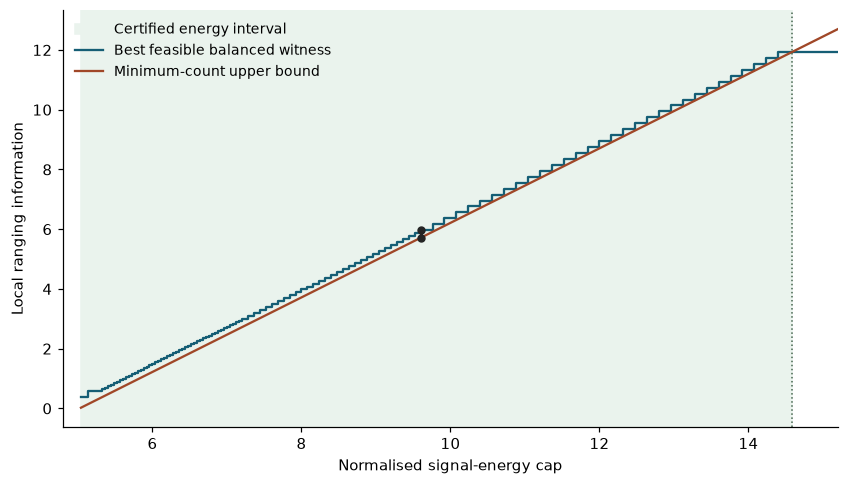

In [8]:
energy_study = study_inputs["energy_witnesses"]
energy_ref = figure_data["mechanism_example"]

# For exactly m_min communication shots: E_comm >= u C - v m_min.
u = Fraction(energy_study["communication_dual_price"])
v = max(u * o.exponent - o.energy for o in options)
comm_lower = u * C - v * minimum
slope = max(o.weight * o.frequency**2 / o.energy for o in options)
brightest = max(o.exponent for o in options)
min_design_energy = minimum * min(o.energy for o in options if o.exponent == brightest)

# Each archived witness uses one central communication option and balanced ranging pairs.
intervals = []
for centre_idx, m, left_idx, right_idx, pairs in energy_study["rows"]:
    comm_mode = options[centre_idx]
    left_mode, right_mode = options[left_idx], options[right_idx]
    assert m > minimum and m * comm_mode.exponent >= C and m + 2 * pairs <= M
    assert left_mode.frequency == -right_mode.frequency and left_mode.weight == right_mode.weight
    energy = m * comm_mode.energy + pairs * (left_mode.energy + right_mode.energy)
    score = 2 * pairs * right_mode.weight * right_mode.frequency**2
    start = max(min_design_energy, energy)
    stop = comm_lower + score / slope   # Strict score advantage for E < stop.
    assert start < stop
    intervals.append((start, stop, score))

intervals.sort()
start, stop, _ = intervals[0]
for lo, hi, _ in intervals[1:]:
    assert lo <= stop, "Gap between two witness intervals"
    stop = max(stop, hi)
assert [str(start), str(stop)] == energy_study["interval_exact"]
triples = [[str(x) for x in entry] for entry in intervals]
# The digest checks every exact interval and score against the original study.
interval_bytes = json.dumps(triples, separators=(",", ":")).encode()
assert sha256(interval_bytes).hexdigest() == energy_study["interval_score_triples_sha256"]

# A feasible witness stays feasible at larger caps. Take the best such score at each step.
caps = sorted({lo for lo, _, _ in intervals} | {Fraction("15.2")})
envelope = [max(score for lo, _, score in intervals if lo <= cap) for cap in caps]
x = np.array(caps, dtype=float)
y = np.array(envelope, dtype=float)
np.testing.assert_allclose(x, energy_ref["energy"], rtol=0, atol=1e-12)
np.testing.assert_allclose(y, energy_ref["feasible_envelope"], rtol=0, atol=1e-12)
best_at_E = max(s for lo, _, s in intervals if lo <= E)
bound_at_E = slope * (E - comm_lower)
np.testing.assert_allclose([float(E), float(best_at_E), float(bound_at_E)], energy_ref["main_point"])
print(f"{len(intervals)} intervals from {float(start):.2f} (included) to an exact upper endpoint "
      f"of approximately {float(stop):.8f} (excluded).")
print(f"At E = {float(E):g}: balanced witness {float(best_at_E):.9f}; "
      f"minimum-count upper bound {float(bound_at_E):.9f}.")

fig, ax = plt.subplots(figsize=(7.6, 4.3), layout="constrained")
ax.axvspan(float(start), float(stop), color="#eaf3ed", label="Certified energy interval")
ax.step(x, y, where="post", color="#155e75", label="Best feasible balanced witness")
ax.plot(x, float(slope) * (x - float(comm_lower)), color="#a04728", label="Minimum-count upper bound")
ax.vlines(float(E), float(bound_at_E), float(best_at_E), color="#242424", lw=2)
ax.scatter([float(E)] * 2, [float(bound_at_E), float(best_at_E)], s=20, color="#242424", zorder=3)
ax.axvline(float(stop), ls=":", color="#46654f", lw=1)
ax.set(xlabel="Normalised signal-energy cap", ylabel="Local ranging information", xlim=(4.8, 15.2))
ax.legend(loc="upper left", fontsize=9)
plt.show()

## Matched source comparisons (Figure 5.3)

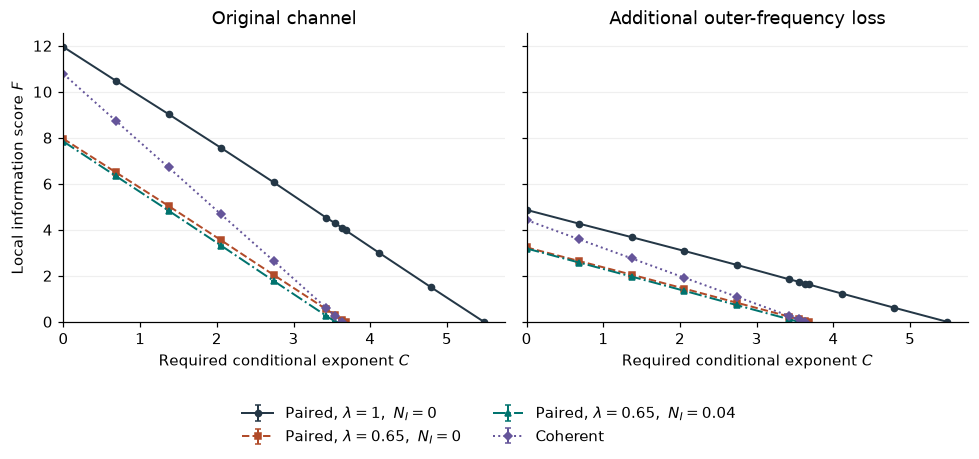

In [9]:
# Markers give saved feasible scores. Whiskers reach the certified upper bounds.
def bound_whiskers(scores, upper):
    scores, upper = np.asarray(scores), np.asarray(upper)
    assert np.all(upper >= scores - 1e-12)
    return np.array([np.zeros_like(scores), np.maximum(upper - scores, 0)])

sources = [
    ("ideal", r"Paired, $\lambda=1,\ N_I=0$", "#243746", "o", "-"),
    ("cold_loss", r"Paired, $\lambda=0.65,\ N_I=0$", "#b14b29", "s", "--"),
    ("noisy_idler", r"Paired, $\lambda=0.65,\ N_I=0.04$", "#00736e", "^", "-."),
    ("coherent", "Coherent", "#65559a", "D", ":"),
]
curves = figure_data["matched_frontiers"]["curves"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, profile, title in zip(axes, ["original", "edge_loss"],
                              ["Original channel", "Additional outer-frequency loss"]):
    for source, label, color, marker, linestyle in sources:
        row = curves[f"{profile}|{source}"]
        ax.errorbar(row["C"], row["feasible"], yerr=bound_whiskers(row["feasible"], row["upper"]),
                    color=color, marker=marker, linestyle=linestyle, ms=4, lw=1.3, capsize=2,
                    label=label)
    ax.set(title=title, xlabel=r"Required conditional exponent $C$", xlim=(0, None), ylim=(0, None))
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel(r"Local information score $F$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.15, 1, 1))
plt.show()

## Idler loss and noise (Figure 5.4)

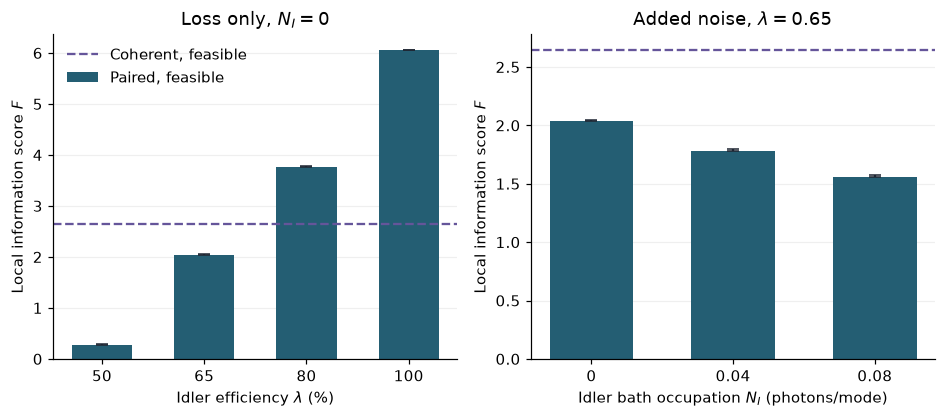

In [10]:
# Scores and ceilings in this sweep come from the archived optimisations.
idler = figure_data["idler_sensitivity"]
controls = [
    (r"(a) Idler loss, $N_I=0$", {"cold_50": "50", "cold_65": "65", "cold_80": "80", "ideal": "100"},
     r"Idler efficiency $\lambda$ (%)", r"Loss only, $N_I=0$"),
    (r"(b) Noise, $\lambda=0.65$", {"cold_65": "0", "noisy_04": "0.04", "noisy_08": "0.08"},
     r"Idler bath occupation $N_I$ (photons/mode)", r"Added noise, $\lambda=0.65$"),
]
fig, axes = plt.subplots(1, 2, figsize=(8.7, 3.9))
for ax, (key, ticks, xlabel, title) in zip(axes, controls):
    row = idler[key]
    x = np.arange(len(row["sources"]))
    ax.bar(x, row["scores"], color="#245e73", width=0.59, label="Paired, feasible")
    ax.errorbar(x, row["scores"], yerr=bound_whiskers(row["scores"], row["upper"]),
                fmt="none", ecolor="#1f2633", capsize=4)
    ax.axhline(row["coherent_feasible"], color="#65559a", ls="--", label="Coherent, feasible")
    ax.set_xticks(x, [ticks[source] for source in row["sources"]])
    ax.set(title=title, xlabel=xlabel, ylabel=r"Local information score $F$", ylim=(0, None))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## Memory lifetime and source comparison (Figure 5.5)

In [11]:
# Separate study: 100,000 preparations, 4,000 energy units, 3 µs hold and 90% transfer.
M_mem = memory["preparation_cap"]
E_mem, C_mem = (Fraction(memory[k]) for k in ("energy_cap", "communication_target"))


def feasible_memory_score(candidate, options):
    c, s = candidate["c"], candidate["s"]
    assert all(type(v) is int and v >= 0 for v in c + s)
    rows = list(zip(c, s, options, strict=True))
    energy = sum((nc + ns) * o["energy"] for nc, ns, o in rows)
    exponent = sum(nc * o["xi"] for nc, _, o in rows)
    assert sum(c + s) <= M_mem and energy <= E_mem and exponent >= C_mem
    frequencies = [o["index"] for _, _, o in rows]
    phase_weights = [ns * o["w"] for _, ns, o in rows]
    score = ranging_score(frequencies, phase_weights)
    assert score == Fraction(candidate["score"])
    return score


def memory_ceiling(certificate, options, count=None):
    # These inequalities bound every allowed option by its resource prices.
    alpha, beta, gamma, delta, centre = (
        Fraction(certificate[key]) for key in ("alpha", "beta", "gamma", "delta", "centre")
    )
    assert min(alpha, beta, gamma) >= 0 and certificate["comm_count"] == count
    assert count is not None or delta == 0
    for option in options:
        price = alpha + beta * option["energy"]
        assert price >= option["w"] * (option["index"] - centre)**2
        assert price + delta >= gamma * option["xi"]
    ceiling = alpha * M_mem + beta * E_mem - gamma * C_mem + delta * (count or 0)
    assert ceiling == Fraction(certificate["upper"])
    return ceiling


memory_results = {}
for study in memory["studies"]:
    by_source = {}
    for family, record in study["families"].items():
        options_mem = [{key: Fraction(value) for key, value in o.items()} for o in record["options"]]
        minimum_count = ceil(C_mem / max(o["xi"] for o in options_mem))
        assert sum(record["restricted"]["c"]) == minimum_count
        restricted_mem = feasible_memory_score(record["restricted"], options_mem)
        best_mem = feasible_memory_score(record["joint"], options_mem)
        upper_mem = memory_ceiling(record["joint_upper"], options_mem)
        upper_min_mem = memory_ceiling(record["minimum_class_upper"], options_mem, minimum_count)
        assert restricted_mem <= upper_min_mem and restricted_mem <= best_mem <= upper_mem
        gain = max(Fraction(0), 100 * (best_mem / upper_min_mem - 1))
        by_source[family] = {"score": best_mem, "upper_bound": upper_mem, "gain_percent": gain}
    memory_results[study["case"]] = {"lifetime_us": study["lifetime_us"], **by_source}

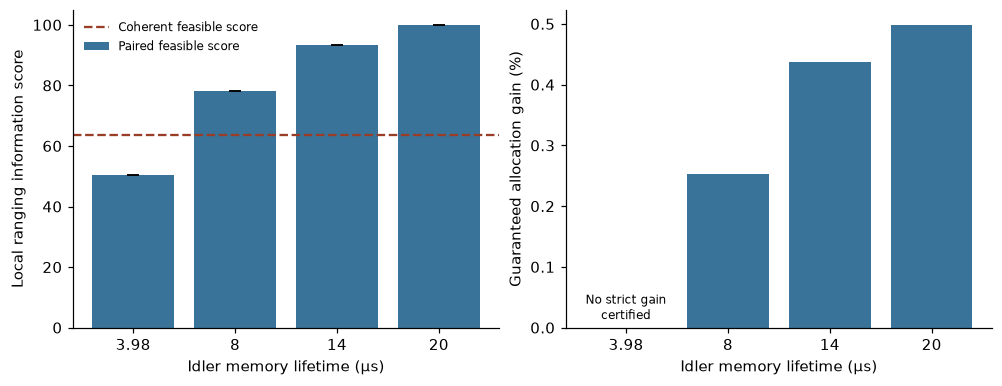

At 3.98 µs the coherent feasible score 63.61392 exceeds the paired upper bound 50.45182.
At 14 µs the paired allocation gain is at least 0.4373%.


In [12]:
# Only the first lifetime is experimentally informed. Whiskers show certified score ceilings.
lifetimes = list(memory_results.values())
times = [case["lifetime_us"] for case in lifetimes]
x = range(len(times))
paired_cases = [case["paired"] for case in lifetimes]
paired = [float(p["score"]) for p in paired_cases]
upper_error = [float(p["upper_bound"] - p["score"]) for p in paired_cases]
gain = [float(p["gain_percent"]) for p in paired_cases]
coherent = [case["coherent"]["score"] for case in lifetimes]
assert len(set(coherent)) == 1

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
axes[0].bar(x, paired, yerr=[[0] * len(times), upper_error], capsize=4,
            color="#39739a", label="Paired feasible score")
axes[0].axhline(float(coherent[0]), color="#993d27", ls="--", label="Coherent feasible score")
axes[0].set_ylabel("Local ranging information score")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].bar(x, gain, color="#39739a")
axes[1].text(0, .014, "No strict gain\ncertified", ha="center", fontsize=8)
axes[1].set_ylabel("Guaranteed allocation gain (%)")
for ax in axes:
    ax.set_xticks(x, [f"{t:.2f}".rstrip("0").rstrip(".") for t in times])
    ax.set_xlabel("Idler memory lifetime (µs)")
plt.show()

reference_case = memory_results["reference_memory"]
longer_lifetime = memory_results["baseline"]  # 14 µs, assumed
assert reference_case["coherent"]["score"] > reference_case["paired"]["upper_bound"]
assert longer_lifetime["paired"]["score"] > longer_lifetime["coherent"]["upper_bound"]

print(f"At {reference_case['lifetime_us']:.2f} µs the coherent feasible score "
      f"{float(reference_case['coherent']['score']):.5f} exceeds "
      f"the paired upper bound {float(reference_case['paired']['upper_bound']):.5f}.")
print(f"At {longer_lifetime['lifetime_us']:g} µs the paired allocation gain is at least "
      f"{outward_percent(longer_lifetime['paired']['gain_percent'])}.")

## Steering and phase diffusion (Figure 5.6)

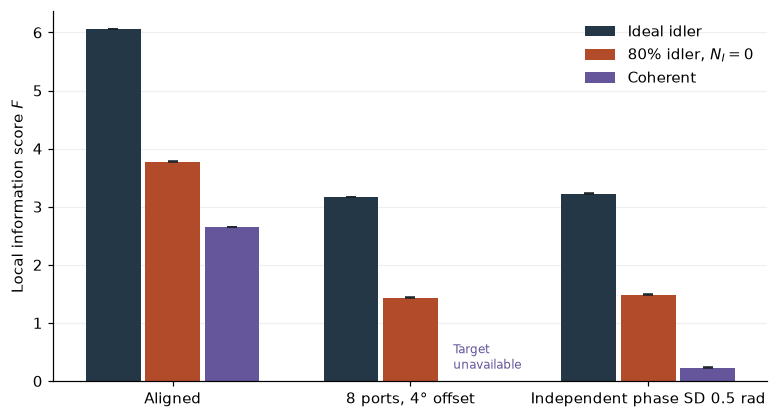

In [13]:
# The coherent source fails the communication target for the steering case.
impairments = figure_data["selected_impairments"]
cases = ["aligned", "array_8_4", "phase_0.5"]
sources = [("ideal", "Ideal idler", "#243746"),
           ("cold08", r"80% idler, $N_I=0$", "#b14b29"),
           ("coherent", "Coherent", "#65559a")]
fig, ax = plt.subplots(figsize=(7.3, 3.9))
for shift, (key, label, color) in zip([-0.25, 0, 0.25], sources):
    row = impairments[key]
    assert row["cases"] == cases
    x = np.arange(len(cases)) + shift
    ok = np.asarray(row["available"], dtype=bool)
    feasible, upper = np.asarray(row["scores"])[ok], np.asarray(row["upper"])[ok]
    ax.bar(x[ok], feasible, color=color, width=0.23, label=label)
    ax.errorbar(x[ok], feasible, yerr=bound_whiskers(feasible, upper),
                fmt="none", ecolor="#182127", capsize=3)
    for position in x[~ok]:
        ax.text(position - 0.07, 0.14, "Target\nunavailable", ha="left", va="bottom", fontsize=8,
                color=color)
ax.set_xticks(range(3), ["Aligned", "8 ports, 4° offset", "Independent phase SD 0.5 rad"])
ax.set_ylabel(r"Local information score $F$")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Timing uncertainty and weak-return designs (Figure 5.7)

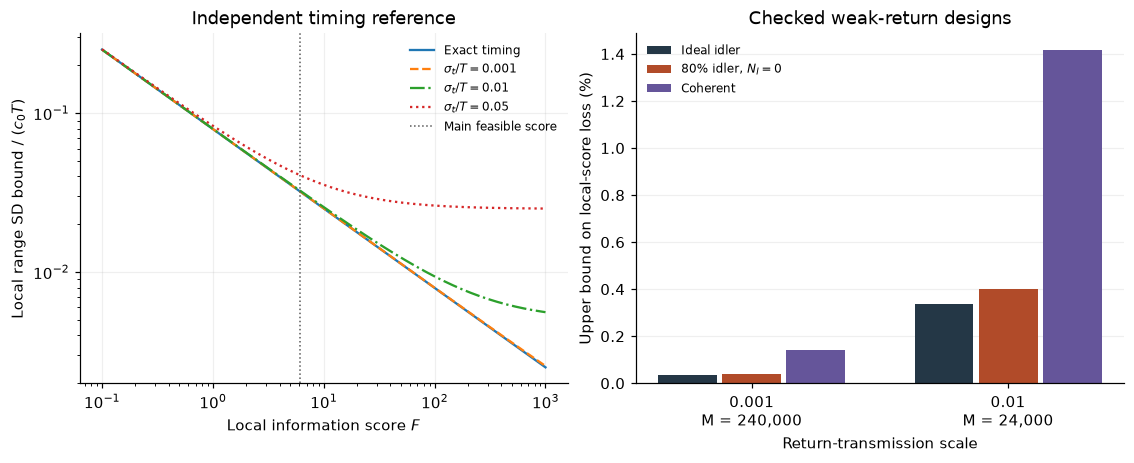

18 designs meet the exact targets. The score loss is at most 1.4170% in these cases.


In [14]:
timing = figure_data["timing_and_weak_design"]
scores = np.asarray(timing["F_grid"])
fig, (ax_time, ax_loss) = plt.subplots(1, 2, figsize=(10.2, 4.1), layout="constrained")

# Independent timing variance adds to the local delay variance. Range is c₀ times half the delay.
for (ratio, saved), linestyle in zip(timing["timing_SD_bounds"].items(), ["-", "--", "-.", ":"]):
    sigma_over_T = float(ratio)
    range_sd = np.sqrt(1 / (16 * np.pi**2 * scores) + sigma_over_T**2 / 4)
    np.testing.assert_allclose(range_sd, saved, rtol=1e-12, atol=0)
    label = "Exact timing" if sigma_over_T == 0 else rf"$\sigma_t/T={ratio}$"
    ax_time.loglog(scores, range_sd, ls=linestyle, lw=1.5, label=label)
assert np.isclose(float(F_full), timing["main_score_marker"])
ax_time.axvline(float(F_full), color="0.35", ls=":", lw=1, label="Main feasible score")
ax_time.set(title="Independent timing reference", xlabel=r"Local information score $F$",
            ylabel=r"Local range SD bound / $(c_0 T)$")
ax_time.legend(fontsize=8, frameon=False)
ax_time.grid(which="major", alpha=0.2)

# Re-evaluate the relative loss using the saved exact-coefficient score and upper certificate.
weak_cases = study_inputs["weak_cases"]
loss_by_group = {}
for row in weak_cases:
    assert row["count"] <= row["M"] and Fraction(row["energy"]) <= Fraction(row["E"])
    assert Fraction(row["exponent"]) >= Fraction(row["C"])
    loss = 100 * (1 - Fraction(row["safe_score"]) / Fraction(row["reference_upper"]))
    group = loss_by_group.setdefault((row["source"], row["scale"]), {})
    target_fraction = Fraction(row["fraction"])
    assert target_fraction not in group
    group[target_fraction] = loss

scales = timing["scales"]
x = np.arange(len(scales))
for offset, (key, label, color) in zip([-0.25, 0, 0.25], [
    ("ideal", "Ideal idler", "#243746"), ("cold08", r"80% idler, $N_I=0$", "#b14b29"),
    ("coherent", "Coherent", "#65559a")]):
    groups = [loss_by_group[key, scale] for scale in scales]
    assert all(set(g) == {Fraction(1, 4), Fraction(1, 2), Fraction(3, 4)} for g in groups)
    maxima = [float(max(g.values())) for g in groups]
    np.testing.assert_allclose(maxima, timing["maximum_loss_upper_percent"][key], rtol=1e-12)
    ax_loss.bar(x + offset, maxima, width=0.23, color=color, label=label)
tick_labels = []
for scale in scales:
    count_limits = {row["M"] for row in weak_cases if row["scale"] == scale}
    assert len(count_limits) == 1
    count_limit, = count_limits
    tick_labels.append(f"{scale}\nM = {count_limit:,}")
ax_loss.set_xticks(x, tick_labels)
ax_loss.set(title="Checked weak-return designs", xlabel="Return-transmission scale",
            ylabel="Upper bound on local-score loss (%)")
ax_loss.set_axisbelow(True)
ax_loss.grid(axis="y", alpha=0.2)
ax_loss.legend(frameon=False, fontsize=8)
plt.show()

worst = max(max(group.values()) for group in loss_by_group.values())
print(f"{len(weak_cases)} designs meet the exact targets. The score loss is at most "
      f"{ceil(10_000 * worst) / 10_000:.4f}% in these cases.")